# 070 CASE 080 — Cloud optical thickness: filtering clouds (SDL 2.0)

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** Which pixels in a partly cloudy scene are clear enough to use?

**Area:** Forest landscape in Västerbotten (Norrland) on a partly cloudy day, 19 July 2024.

**Partners:** RISE, SMHI, AI Sweden

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open. COT models from Pirinen et al., *Remote Sensing* 16(4):694, 2024 ([code](https://github.com/DigitalEarthSwedenExperimentalLab/ml-cloud-opt-thick), Apache-2.0).

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes about a minute on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
AOI + date → fetch_des_data → COTAnalyzer (ensemble of MLP5 models) → cloud optical thickness per pixel → thresholds
```

The cloud optical thickness (COT) models come from SDL 2.0: RISE and AI Sweden trained them on
SMHI's radiative-transfer simulations, and in 2024 they were sent into orbit. `COTAnalyzer` estimates
COT per pixel from the spectral bands and classes pixels as clear, thin cloud (COT ≥ 0.015) or thick
cloud (COT ≥ 0.025), the thresholds from the paper. A user can choose a stricter or looser cut.
Code: [ml-cloud-opt-thick](https://github.com/DigitalEarthSwedenExperimentalLab/ml-cloud-opt-thick).

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 19.00, "south": 64.50, "east": 19.50, "north": 64.80}
DATE = "2024-07-19"

scene = load_scene(DATE, AOI, max_cloud=1.0)  # keep clouds: they are the subject

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 51.3%


2024-07-19: 11 bands, 3499 x 2610 px at 10 m, cloud 51.3% (SCL), CRS EPSG:3006


## 3. Estimate cloud optical thickness

In [3]:
from imint.analyzers.cot import COTAnalyzer

res = COTAnalyzer({}).run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                          output_dir="outputs/080", scl=scene.scl, geo=scene.geo)
print(res.summary())
cot = np.asarray(res.outputs["cot_map"], dtype=float)
cloud_class = np.asarray(res.outputs["cloud_class"])  # 0 clear, 1 thin, 2 thick
thin_t, thick_t = res.metadata["thin_threshold"], res.metadata["thick_threshold"]
stats = res.outputs["stats"]
print(f"COT classes (thin ≥ {thin_t}, thick ≥ {thick_t}): clear {stats['clear_fraction']:.1%}, "
      f"thin {stats['thin_cloud_fraction']:.1%}, thick {stats['thick_cloud_fraction']:.1%}")
scl_cloud = np.isin(scene.scl, [8, 9, 10]).mean()
print(f"For comparison, scene classification (SCL 8–10) marks {scl_cloud:.1%} as cloud")
agree = (cloud_class > 0) == np.isin(scene.scl, [8, 9, 10])
print(f"COT and SCL agree on cloud / not cloud for {agree.mean():.1%} of pixels")

[cot] OK — outputs: cot_map, cloud_class, stats
COT classes (thin ≥ 0.015, thick ≥ 0.025): clear 58.0%, thin 11.2%, thick 30.8%
For comparison, scene classification (SCL 8–10) marks 43.4% as cloud
COT and SCL agree on cloud / not cloud for 85.2% of pixels


## 4. Results

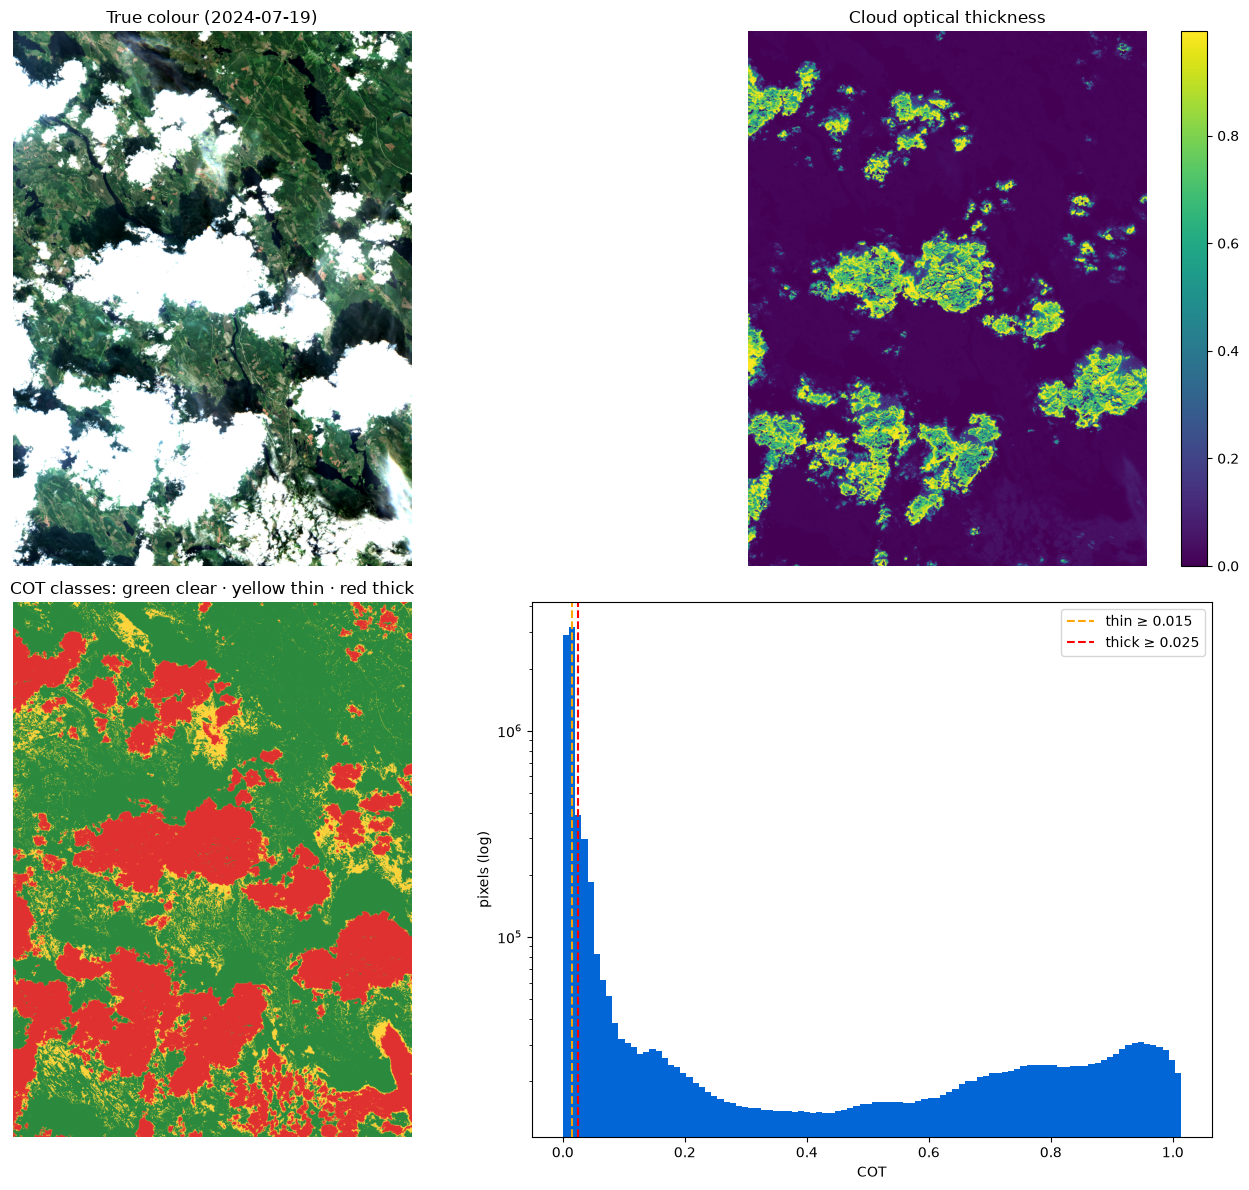

In [4]:
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes[0, 0].imshow(scene.rgb); axes[0, 0].set_title(f"True colour ({DATE})")
im = axes[0, 1].imshow(cot, cmap="viridis", vmin=0, vmax=np.nanpercentile(cot, 99))
axes[0, 1].set_title("Cloud optical thickness")
fig.colorbar(im, ax=axes[0, 1], fraction=0.046)
axes[1, 0].imshow(cloud_class, cmap=ListedColormap(["#2b8a3e", "#ffd43b", "#e03131"]), vmin=0, vmax=2)
axes[1, 0].set_title("COT classes: green clear · yellow thin · red thick")
for ax in axes.flat[:3]:
    ax.axis("off")
axes[1, 1].hist(cot.ravel(), bins=100, range=(0, np.nanpercentile(cot, 99.5)), color="#0366d6", log=True)
axes[1, 1].axvline(thin_t, color="orange", linestyle="--", label=f"thin ≥ {thin_t}")
axes[1, 1].axvline(thick_t, color="red", linestyle="--", label=f"thick ≥ {thick_t}")
axes[1, 1].set_xlabel("COT"); axes[1, 1].set_ylabel("pixels (log)"); axes[1, 1].legend()
plt.tight_layout()
plt.show()

## 5. Interpretation

COT gives a graded measure where the standard scene classification only says cloud or not cloud.
Comparing the two shows where they disagree, typically at cloud edges and in thin cloud, which can
still bias vegetation indices. Lowering the thresholds removes more of it at the cost of fewer
usable pixels.

**Links:** [`imint/analyzers/cot.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/cot.py) ·
[paper](https://www.mdpi.com/2072-4292/16/4/694)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).